# Optimal policy with and without a price markup

`fixed_wage_cohorts.ipynb` is the model: time to produce, cohorts committed at $y^{ss}_i$ for
$\tau_i>t$, and a nominal wage pinned at $W^{ss}$.  This notebook runs that model **twice** --
once with price $=$ marginal cost ($\mu=1$) and once with the monopolistic-competition markup
($\mu=\sigma/(\sigma-1)=1.25$) -- and puts the two optimal-policy answers side by side.

The point is that $\mu$ splits the model cleanly in two:

* **the positive side is markup-invariant.**  $\mu$ is common to every firm, so it cancels from
  every relative price $p_i/P$, from the CES ratio $P_t/P^{ss}$, and therefore from every log
  deviation.  Impulse responses and the neutrality of the rate under a flexible wage are
  identical at any $\mu$.  Section 3 checks this.
* **the normative side is not.**  $\mu$ sets where the steady state sits relative to efficient
  ($L$ is $5.4\%$ too low at $\mu=1.25$), and the fixed wage lets the rate move activity.  So
  the planner acquires a reason to deviate from $\rho$ that has nothing to do with any shock.

Section 5 is the slide.

In [1]:
import numpy as np
import pandas as pd
from types import SimpleNamespace
from scipy.optimize import root, minimize
import matplotlib.pyplot as plt

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to `fixed_wage_cohorts.ipynb`, and $\mu$ plays no part in it: the production lags come
from inventory/COGS data and the discount-factor wedge, neither of which touches pricing.

In [2]:
INVENTORY_TO_COGS_SCALING = 36.5
NOMINAL_INTEREST_RATE     = 0.01

sigma = 5.0; gamma = 2.0; eta = 2.0; chi = 1.0
beta    = 1 / (1.0 + NOMINAL_INTEREST_RATE)
beta1   = 1 / (1.0 + NOMINAL_INTEREST_RATE * np.exp(30 / (INVENTORY_TO_COGS_SCALING * 0.9)))
beta_hh = beta
rho     = 1 / beta - 1
T       = 30

data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * INVENTORY_TO_COGS_SCALING / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000); tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf; continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N; tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N); pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]; tau[tau < 0] = 0

TVALS  = tau.astype(int).to_numpy(); N_ARRAY = np.array(N)
kappa  = c; NF = len(TVALS); TAUMAX = int(TVALS.max())
ZETA   = kappa ** TVALS * (TVALS + N_ARRAY)

FREE = TVALS[None, :] <= np.arange(T)[:, None]
SMAT = np.maximum(np.arange(T)[:, None] - TVALS[None, :], 0)
TPT  = np.arange(T)[:, None] + TVALS[None, :]
DISC = beta_hh ** np.arange(T)

print(f'kappa = {kappa:.6f}   n = {NF}   tau in [0, {TAUMAX}]   T = {T}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_83838/1806413801.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


kappa = 0.901802   n = 269   tau in [0, 13]   T = 30


## 2. The model, with $\mu$ as an argument

`fixed_wage_cohorts.ipynb`'s `steady`/`alloc`/`solve`, wrapped so the markup can be set rather
than hardcoded.  $\mu$ appears in exactly two places -- steady-state labour and the free firms'
pricing rule -- which is the whole content of section 3.

In [3]:
def build_economy(mu):
    """The fixed-wage cohort economy at a given gross markup mu = price / marginal cost.

    mu = 1                 perfect competition, price = marginal cost
    mu = sigma/(sigma-1)   monopolistic competition, the textbook CES markup
    """
    def steady(A=1.0, W=1.0):
        z   = beta ** TVALS * ZETA * A
        At  = np.sum(z ** (sigma - 1)) ** (1 / (sigma - 1))
        Lam = np.sum(z ** (sigma - 1) * beta ** TVALS)
        Th  = At ** sigma / Lam
        L   = (At / (mu * chi * Th ** gamma)) ** (1 / (gamma + eta)); Y = Th * L
        p   = mu * W / z; P = np.sum(p ** (1 - sigma)) ** (1 / (1 - sigma))
        y   = (p / P) ** (-sigma) * Y
        return dict(A_til=At, Theta=Th, L=L, Y=Y, C=Y, W=W, P=P, p=p, y=y,
                    l=y / (ZETA * A), omega=W / P)

    SS    = steady()
    S_QTY = np.array([np.sum(SS['y'][~FREE[t]] ** ((sigma - 1) / sigma)) for t in range(T)])
    Y_FLR = S_QTY ** (sigma / (sigma - 1))

    def alloc(W, Y, i_path, A_path):
        pad = TAUMAX + 2
        Wx = np.r_[W, np.full(pad, SS['W'])]; Ax = np.r_[A_path, np.full(pad, A_path[-1])]
        ix = np.r_[i_path, np.full(pad, rho)]; cd = np.r_[1.0, np.cumprod(1.0 / (1.0 + ix))]
        p_f = mu * Wx[SMAT] / ((cd[np.arange(T)][:, None] / cd[SMAT]) * ZETA[None, :] * Ax[SMAT])
        Q   = np.sum(np.where(FREE, p_f ** (1 - sigma), 0.0), axis=1)
        P   = (Q / (1.0 - S_QTY * Y ** ((1 - sigma) / sigma))) ** (1 / (1 - sigma))
        y   = np.where(FREE, (p_f / P[:, None]) ** (-sigma) * Y[:, None], SS['y'][None, :])
        p   = np.where(FREE, p_f, P[:, None] * (SS['y'][None, :] / Y[:, None]) ** (-1 / sigma))
        yx  = np.vstack([y, np.tile(SS['y'], (pad, 1))])
        l   = yx[TPT, np.arange(NF)] / (ZETA * Ax[:T, None])
        return P, p, y, l, l.sum(axis=1)

    _WARM = {}
    def solve(i_path=None, A_path=None, xi=None, phi=1.0, key=None):
        i_path = np.full(T, rho) if i_path is None else np.asarray(i_path, float)
        A_path = np.ones(T)      if A_path is None else np.asarray(A_path, float)
        xi     = np.zeros(T)     if xi     is None else np.asarray(xi, float)

        def resid(u):
            W = np.exp(u[:T]); Y = Y_FLR + np.exp(u[T:])
            P, _, _, _, L = alloc(W, Y, i_path, A_path)
            Px = np.r_[P, SS['P']]; Yx = np.r_[Y, SS['Y']]; xix = np.r_[xi, 0.0]
            wage = (1 - phi) * (np.log(W / P)
                                - (np.log(chi) + eta*np.log(L) + gamma*np.log(Y))) \
                 + phi * (np.log(W) - np.log(SS['W']))
            eu = (xix[:T] - gamma*np.log(Yx[:T]) - np.log(Px[:T])) \
               - (np.log(beta_hh) + np.log(1 + i_path) + xix[1:]
                  - gamma*np.log(Yx[1:]) - np.log(Px[1:]))
            return np.r_[wage, eu]

        u0 = _WARM.get(key, np.r_[np.full(T, np.log(SS['W'])), np.log(SS['Y'] - Y_FLR)])
        s  = root(resid, u0, method='hybr', tol=1e-13)
        if s.success and key is not None: _WARM[key] = s.x
        W = np.exp(s.x[:T]); Y = Y_FLR + np.exp(s.x[T:])
        P, p, y, l, L = alloc(W, Y, i_path, A_path)
        return dict(W=W, Y=Y, C=Y, P=P, p=p, y=y, l=l, L=L, i=i_path, A=A_path, xi=xi,
                    phi=phi, omega=W / P, ok=s.success, res=float(np.max(np.abs(s.fun))),
                    pi=np.r_[np.log(P[0] / SS['P']), np.diff(np.log(P))],
                    welfare=float(np.sum(DISC * np.exp(xi) *
                                  (Y**(1-gamma)/(1-gamma) - chi*L**(1+eta)/(1+eta)))))

    def cons_equiv(U_alt, s_base):
        w  = DISC * np.exp(s_base['xi'])
        UC = float(np.sum(w * s_base['Y'] ** (1 - gamma) / (1 - gamma)))
        UN = float(np.sum(w * chi * s_base['L'] ** (1 + eta) / (1 + eta)))
        return float(((U_alt + UN) / UC) ** (1.0 / (1.0 - gamma)) - 1.0)

    return SimpleNamespace(mu=mu, SS=SS, solve=solve, alloc=alloc, steady=steady,
                           Y_FLR=Y_FLR, cons_equiv=cons_equiv)


XI_D = np.r_[-0.01, np.zeros(T - 1)]      # 1 % contractionary demand shock
A_1P = np.r_[0.97,  np.ones(T - 1)]       # 3 % TFP hit to the batches started at t = 0
CASES = {'no shock': {}, 'demand shock': dict(xi=XI_D), 'TFP shock': dict(A_path=A_1P)}

MU_C, MU_M = 1.0, sigma / (sigma - 1)
EC = {MU_C: build_economy(MU_C), MU_M: build_economy(MU_M)}
LBL = {MU_C: 'price = marginal cost', MU_M: f'{100*(MU_M-1):.0f}% markup'}

print(f'{"economy":<32}{"L":>12}{"Y":>12}{"W/P":>12}')
print('-' * 68)
for m, ec in EC.items():
    print(f'{f"mu = {m:.2f}  ({LBL[m]})":<32}'
          f'{ec.SS["L"]:>12.6f}{ec.SS["Y"]:>12.6f}{ec.SS["omega"]:>12.4f}')
print(f'\nthe markup lowers steady-state employment by '
      f'{100*(EC[MU_M].SS["L"]/EC[MU_C].SS["L"] - 1):.2f}%  '
      f'and raises the real wage by exactly mu ({EC[MU_C].SS["omega"]/EC[MU_M].SS["omega"]:.4f})')

economy                                    L           Y         W/P
--------------------------------------------------------------------
mu = 1.00  (price = marginal cost)    0.434343   11.935519     26.8750
mu = 1.25  (25% markup)             0.410776   11.287917     21.5000

the markup lowers steady-state employment by -5.43%  and raises the real wage by exactly mu (1.2500)


## 3. The positive side does not depend on $\mu$

$\mu$ multiplies every firm's price by the same constant, so it cancels from $p_i/P$, from
$P_t/P^{ss}$, and from every log deviation.  Two checks: the shock IRFs, and the same rate path
run in both economies.

In [4]:
ref = {}
print('shock IRFs, rate pegged at rho (log deviations from each economy\'s own steady state)')
for nm, kw in CASES.items():
    if nm == 'no shock': continue
    for m, ec in EC.items():
        s = ec.solve(np.full(T, rho), phi=1.0, **kw)
        v = np.array([np.log(s['Y']/ec.SS['Y']), np.log(s['L']/ec.SS['L']),
                      np.log(s['P']/ec.SS['P']), np.log(s['omega']/ec.SS['omega'])])
        if m == MU_C:
            ref[nm] = v
            print(f'   {nm:<14} mu = 1.00  peak dlogY {100*np.max(np.abs(v[0])):.4f}%   (reference)')
        else:
            print(f'   {nm:<14} mu = {m:.2f}  peak dlogY {100*np.max(np.abs(v[0])):.4f}%   '
                  f'max |difference| over Y, L, P, W/P = {np.max(np.abs(v - ref[nm])):.2e}')

print('\nthe SAME rate path in both economies (no shock):')
i_try = np.r_[[0.0107, 0.00577, 0.00203, 0, 0, 0, 0, 0], np.full(T - 8, rho)]
vr = None
for m, ec in EC.items():
    s = ec.solve(i_try, phi=1.0)
    v = np.array([np.log(s['Y']/ec.SS['Y']), np.log(s['L']/ec.SS['L']), np.log(s['P']/ec.SS['P'])])
    tag = '(reference)' if vr is None else f'max |difference| = {np.max(np.abs(v - vr)):.2e}'
    if vr is None: vr = v
    print(f'   mu = {m:.2f}   peak dlogY {100*np.max(np.abs(v[0])):.4f}%   '
          f'peak dlogL {100*np.max(np.abs(v[1])):.4f}%   {tag}')
print('\n   -> identical.  mu moves steady-state LEVELS only; it cannot be seen in deviations.')

shock IRFs, rate pegged at rho (log deviations from each economy's own steady state)
   demand shock   mu = 1.00  peak dlogY 0.0430%   (reference)
   demand shock   mu = 1.25  peak dlogY 0.0430%   max |difference| over Y, L, P, W/P = 8.89e-16


   TFP shock      mu = 1.00  peak dlogY 1.0825%   (reference)


   TFP shock      mu = 1.25  peak dlogY 1.0825%   max |difference| over Y, L, P, W/P = 3.32e-15

the SAME rate path in both economies (no shock):
   mu = 1.00   peak dlogY 2.9862%   peak dlogL 5.8311%   (reference)
   mu = 1.25   peak dlogY 2.9862%   peak dlogL 5.8311%   max |difference| = 2.32e-15

   -> identical.  mu moves steady-state LEVELS only; it cannot be seen in deviations.


## 4. The normative side does

Optimal nominal rate: $\max_i U$ over the first `L_USE` periods, with the rate pegged back at
$\rho$ afterwards and bounded in $[0, 5\%]$.  Solved three times per economy -- once with **no
shock**, which isolates any level channel, and once per shock.

A well-posed stabilisation problem returns $i^*=\rho$ with no shock.  One with a level
distortion does not.

In [5]:
I_LO, I_HI, L_USE = 0.0, 0.05, 8

def full_path(ip):
    return np.r_[np.asarray(ip, float), np.full(T - len(ip), rho)]

def optimise(ec, kw, L=L_USE):
    def neg_U(ip):
        s = ec.solve(full_path(ip), phi=1.0, key=None, **kw)
        return 1e3 if (not s['ok'] or not np.isfinite(s['welfare'])) else -s['welfare']
    best = None
    for sd in (np.full(L, rho), np.full(L, 0.005)):
        r = minimize(neg_U, sd, method='L-BFGS-B', bounds=[(I_LO, I_HI)] * L,
                     options={'maxiter': 2000, 'ftol': 1e-16, 'gtol': 1e-12})
        if best is None or r.fun < best.fun: best = r
    return best

RES = {}
print(f'{"economy":<32}{"case":<15}{"at bounds":>11}{"CE gain":>11}   i*[:6]')
print('-' * 102)
for m, ec in EC.items():
    for nm, kw in CASES.items():
        b    = optimise(ec, kw)
        peg  = ec.solve(np.full(T, rho), phi=1.0, **kw)
        opt  = ec.solve(full_path(b.x),  phi=1.0, **kw)
        RES[(m, nm)] = dict(ip=full_path(b.x), peg=peg, opt=opt,
                            ce=100 * ec.cons_equiv(opt['welfare'], peg))
        nlo = int(np.sum(np.isclose(b.x, I_LO))); nhi = int(np.sum(np.isclose(b.x, I_HI)))
        print(f'{f"mu = {m:.2f}  ({LBL[m]})":<32}{nm:<15}{f"{nlo}lo/{nhi}hi":>11}'
              f'{RES[(m, nm)]["ce"]:>10.4f}%   {np.round(b.x[:6], 5)}')

print('\nWELFARE DECOMPOSITION  (per cent of steady-state consumption)')
print(f'{"economy":<32}{"total":>10}{"level channel":>16}{"stabilisation":>16}{"level share":>14}')
print('-' * 90)
for m in EC:
    lev = RES[(m, 'no shock')]['ce']
    for nm in ('demand shock', 'TFP shock'):
        tot = RES[(m, nm)]['ce']
        print(f'{f"mu = {m:.2f}  {nm}":<32}{tot:>9.4f}%{lev:>15.4f}%{tot-lev:>15.4f}%'
              f'{(100*lev/tot if abs(tot) > 1e-9 else 0):>13.1f}%')

economy                         case             at bounds    CE gain   i*[:6]
------------------------------------------------------------------------------------------------------


mu = 1.00  (price = marginal cost)no shock           0lo/0hi   -0.0000%   [0.01 0.01 0.01 0.01 0.01 0.01]


mu = 1.00  (price = marginal cost)demand shock       0lo/0hi    0.0001%   [0.00875 0.00972 0.0098  0.00986 0.00991 0.00994]


mu = 1.00  (price = marginal cost)TFP shock          1lo/0hi    0.0107%   [0.      0.01026 0.01167 0.01085 0.01025 0.00999]


mu = 1.25  (25% markup)         no shock           5lo/0hi    0.0910%   [0.0107  0.00577 0.00203 0.      0.      0.     ]


mu = 1.25  (25% markup)         demand shock       5lo/0hi    0.0932%   [0.00938 0.00547 0.00176 0.      0.      0.     ]


mu = 1.25  (25% markup)         TFP shock          6lo/0hi    0.1023%   [0.     0.0062 0.0039 0.     0.     0.    ]

WELFARE DECOMPOSITION  (per cent of steady-state consumption)
economy                              total   level channel   stabilisation   level share
------------------------------------------------------------------------------------------
mu = 1.00  demand shock            0.0001%        -0.0000%         0.0001%         -0.0%
mu = 1.00  TFP shock               0.0107%        -0.0000%         0.0107%         -0.0%
mu = 1.25  demand shock            0.0932%         0.0910%         0.0021%         97.7%
mu = 1.25  TFP shock               0.1023%         0.0910%         0.0113%         89.0%


## 5. The slide

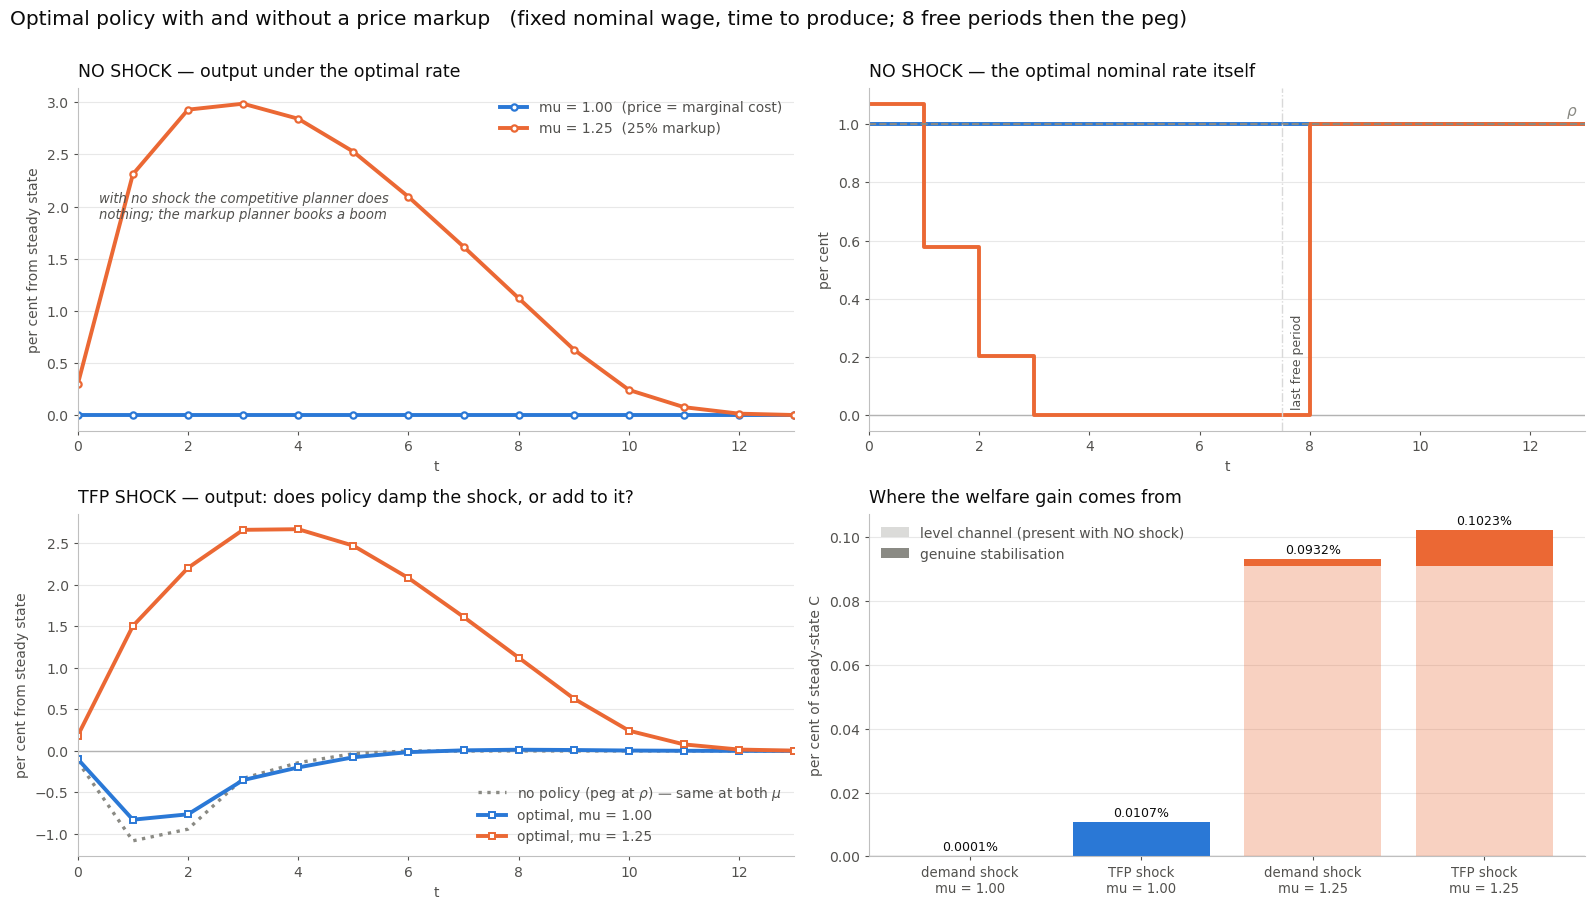

In [6]:
from matplotlib.patches import Patch

BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#8a8a84', '#0b0b0b', '#52514e'
COL = {MU_C: BLUE, MU_M: ORANGE}
H   = 14
t   = np.arange(H)

def style(ax, title, ylab, xlab='t'):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('0.75'); ax.spines['bottom'].set_color('0.75')
    ax.tick_params(colors=MUTED, labelsize=10, length=3)
    ax.grid(axis='y', color='0.91', lw=0.8); ax.set_axisbelow(True)
    ax.axhline(0, color='0.7', lw=1.0, zorder=1)
    ax.set_xlabel(xlab, color=MUTED, fontsize=10); ax.set_ylabel(ylab, color=MUTED, fontsize=10)
    ax.set_title(title, color=INK, fontsize=12.5, loc='left', pad=8)

fig, axes = plt.subplots(2, 2, figsize=(16, 9)); fig.patch.set_facecolor('white')

# -- (0,0) no shock: output ------------------------------------------------------------
ax = axes[0, 0]; style(ax, 'NO SHOCK — output under the optimal rate', 'per cent from steady state')
ax.set_xlim(0, H - 1)
for m in EC:
    r = RES[(m, 'no shock')]
    ax.plot(t, 100 * np.log(r['opt']['Y'] / EC[m].SS['Y'])[:H], color=COL[m], lw=2.8,
            marker='o', ms=4.5, mfc='white', mec=COL[m], mew=1.6,
            label=f'mu = {m:.2f}  ({LBL[m]})')
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc='upper right')
ax.annotate('with no shock the competitive planner does\nnothing; the markup planner books a boom',
            xy=(0.03, 0.62), xycoords='axes fraction', fontsize=9.5, color=MUTED, style='italic')

# -- (0,1) no shock: the rate ----------------------------------------------------------
ax = axes[0, 1]; style(ax, 'NO SHOCK — the optimal nominal rate itself', 'per cent')
ax.set_xlim(0, H - 1)
for m in EC:
    ax.step(t, 100 * RES[(m, 'no shock')]['ip'][:H], where='post', color=COL[m], lw=2.8)
ax.axhline(100 * rho, color=GREY, lw=1.4, ls='--')
ax.annotate(r'$\rho$', xy=(H - 1, 100 * rho), xytext=(-6, 6), textcoords='offset points',
            ha='right', color=GREY, fontsize=11)
ax.axvline(L_USE - 0.5, color='0.85', lw=1.0, ls='-.')
ax.annotate('last free period', xy=(L_USE - 0.5, 0.02), xytext=(6, 0),
            textcoords='offset points', fontsize=9, color=MUTED, rotation=90, va='bottom')

# -- (1,0) TFP shock: output -----------------------------------------------------------
ax = axes[1, 0]; style(ax, 'TFP SHOCK — output: does policy damp the shock, or add to it?',
                       'per cent from steady state')
ax.set_xlim(0, H - 1)
ax.plot(t, 100 * np.log(RES[(MU_C, 'TFP shock')]['peg']['Y'] / EC[MU_C].SS['Y'])[:H],
        color=GREY, lw=2.4, ls=':', label=r'no policy (peg at $\rho$) — same at both $\mu$')
for m in EC:
    r = RES[(m, 'TFP shock')]
    ax.plot(t, 100 * np.log(r['opt']['Y'] / EC[m].SS['Y'])[:H], color=COL[m], lw=2.8,
            marker='s', ms=4.2, mfc='white', mec=COL[m], mew=1.4, label=f'optimal, mu = {m:.2f}')
ax.legend(frameon=False, fontsize=10, labelcolor=MUTED, loc='lower right')

# -- (1,1) welfare decomposition -------------------------------------------------------
ax = axes[1, 1]; style(ax, 'Where the welfare gain comes from', 'per cent of steady-state C', xlab='')
labels, lev, stab, cols = [], [], [], []
for m in EC:
    for nm in ('demand shock', 'TFP shock'):
        labels.append(f'{nm}\nmu = {m:.2f}')
        lev.append(max(RES[(m, 'no shock')]['ce'], 0.0))
        stab.append(RES[(m, nm)]['ce'] - RES[(m, 'no shock')]['ce'])
        cols.append(COL[m])
x = np.arange(len(labels))
ax.bar(x, lev,  color=cols, alpha=0.30, edgecolor='none')
ax.bar(x, stab, bottom=lev, color=cols, edgecolor='none')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9.5, color=MUTED)
# proxy handles: the bars are coloured by economy, so the legend must be colour-neutral
ax.legend(handles=[Patch(facecolor=GREY, alpha=0.30, label='level channel (present with NO shock)'),
                   Patch(facecolor=GREY, label='genuine stabilisation')],
          frameon=False, fontsize=10, labelcolor=MUTED, loc='upper left')
for xi_, l_, s_ in zip(x, lev, stab):
    ax.annotate(f'{l_ + s_:.4f}%', xy=(xi_, l_ + s_), xytext=(0, 4), textcoords='offset points',
                ha='center', fontsize=9, color=INK)

fig.suptitle('Optimal policy with and without a price markup   '
             '(fixed nominal wage, time to produce; 8 free periods then the peg)',
             fontsize=14.5, color=INK, x=0.006, ha='left', y=1.005)
fig.tight_layout()
fig.savefig('../semi_endo_markup_vs_competitive_slide.png', dpi=200, bbox_inches='tight',
            facecolor='white')
plt.show()

## Summary

1. **The markup is invisible in the dynamics.**  Shock IRFs and the response to any rate path are
   identical at $\mu=1$ and $\mu=1.25$ to $\sim\!10^{-15}$.  Whatever the cohort notebooks report
   about how this economy *responds* is unaffected by the markup assumption.

2. **It is decisive for optimal policy.**  With price $=$ marginal cost the steady state is
   efficient, the no-shock optimum is $i^*_t=\rho$ exactly, and the shock rows are pure
   stabilisation.  With a $25\%$ markup, employment is $5.4\%$ below efficient forever, and the
   rate -- which moves $W/P$ one for one because the nominal wage is pinned -- becomes a
   second-best instrument against *that*.

3. **The level channel then swamps the shock.**  The no-shock optimum alone is worth
   $+0.091\%$ of steady-state consumption, against $+0.002\%$ for the entire demand-shock
   stabilisation problem: $98\%$ of the reported "optimal policy" gain is a boom the planner
   would book with no shock present.  It also runs to the zero bound in 5 of 8 free periods and
   does not converge in the length of the free window.

4. **The sign tracks the distortion, not the magnitude of $\mu$.**  $\mu>1$ (under-production)
   buys a cut, $\mu<1$ (a subsidy, over-production) buys a hike, and the planner does nothing
   at $\mu=1$.  The switch is at price $=$ marginal cost, not at any particular markup size.

5. **So the no-shock row is a specification test.**  If the planner moves with no shock present,
   the model contains a non-shock wedge and the optimal-policy figure is not answering the
   stabilisation question.  Run it before reading any optimal-rate result off this model.

Caveat carried over from `fixed_wage_cohorts.ipynb`: the optimum is taken over the first
`L_USE` periods with the rate pegged at $\rho$ afterwards, so it is a constrained optimum.  A
rate held off $\rho$ *forever* is not a steady state in this model -- the Euler equation forces
consumption to decline at $[\log(1+i)-\log(1+\rho)]/\gamma$ per period and the level is set by
the terminal condition -- so uniform-rate comparisons across horizons are not meaningful.